# SAF 2026 问卷数据分析（线 2：运动带来什么，SAF 又带来什么？）

**数据**：`saf-enquesta-2026-equips.xlsx`，UAB 体育活动服务中心（SAF）2026 年 2 月的匿名问卷，共 1,025 份回答。

**这份 notebook 想回答的问题**
1. 数据质量如何？样本有没有结构性偏差？（先排雷，再下结论）
2. **运动本身**带来什么？——运动者 vs 不运动者，以及"运动频率"的剂量-反应关系。
3. **SAF 会员身份**在"运动"之外还额外带来什么？——这是赛题强调的"把运动和成为会员分开"。
4. 这些关联在控制性别、学业阶段、调查波次之后还成立吗？
5. 能给 SAF 的"三条信息"是什么？第二份问卷应该怎么改进？

> ⚠️ **一个贯穿全文的提醒**：这是一次性横断面问卷，只能说明"关联"，**不能证明因果**。
> 例如"运动的人更健康"也可能是"更健康的人更愿意/更能运动"（反向因果）。

## 1. 环境与数据读取

In [1]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 不存在的备选字体不要刷警告
sns.set_style("whitegrid")
# 中文字体：matplotlib>=3.6 支持逐字符回退——拉丁/数字用 DejaVu Sans，汉字回退到后面的 CJK 字体。
# （Droid Sans Fallback 只有汉字、没有拉丁字形，若把它放第一位，数字/字母会显示成方块。）
# 换机器运行时，可在列表里加入本机有的 CJK 字体（SimHei / Microsoft YaHei / PingFang SC / Noto Sans CJK SC）。
plt.rcParams["font.family"] = ["DejaVu Sans", "Droid Sans Fallback", "Noto Sans CJK SC",
                               "SimHei", "Microsoft YaHei", "PingFang SC"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

# 找到数据文件（按需修改）
CANDIDATES = [
    Path("extracted/DADES/saf-enquesta-2026-equips.xlsx"),
    Path("DADES/saf-enquesta-2026-equips.xlsx"),
    Path("saf-enquesta-2026-equips.xlsx"),
]
DATA = next(p for p in CANDIDATES if p.exists())
raw = pd.read_excel(DATA, sheet_name="Respostes")
print("数据文件:", DATA, "| 形状:", raw.shape)

数据文件: extracted/DADES/saf-enquesta-2026-equips.xlsx | 形状: (1025, 33)


原始列名是很长的加泰罗尼亚语问句，不好操作。下面按**列位置**给每一列起一个短名，并配上中文含义。
（`Columnes` 工作表里的"Respostes"一列就是每一列的有效回答数——它已经暗示了跳题逻辑，下一节会展开。）

In [2]:
SHORT = ["id", "onada", "genere", "estudis", "situacio", "abonat", "temps_abonat", "on", "freq", "com",
         "motius", "energia", "motivacio", "concentracio", "organitzacio", "habilitats", "amistats",
         "salut_fisica", "estat_emocional", "factors_malestar", "pss1", "pss2", "pss3", "pss4",
         "hores_son", "descans", "qualitat_son", "pertinenca", "opinio", "creixement", "records",
         "voluntariat", "organs"]
ZH = ["编号", "调查波次(1/2)", "性别", "学业阶段", "运动习惯现状", "是否SAF会员", "加入SAF多久", "在哪里运动(多选)",
      "每周运动频率", "运动方式(多选)", "运动动机(多选)", "运动让我更有精力", "运动让我更想保持健康生活",
      "运动提升专注力", "运动让我更有条理", "运动培养团队/领导力等技能", "因运动结交朋友",
      "自评身体健康", "自评情绪状态", "情绪差的原因(多选)", "PSS-1 无法控制重要的事", "PSS-2 难以应付要做的事",
      "PSS-3 有信心掌控自己的责任(反向题)", "PSS-4 困难累积得太多", "每晚睡眠时长", "醒来有休息好的感觉",
      "睡眠质量自评", "在课堂之外有归属感", "意见被大学重视", "通过大学找到助我成长的活动",
      "与大学里的人有积极回忆", "参加过体育志愿/赛事组织", "参与学生组织/管理机构"]
assert len(SHORT) == raw.shape[1] == len(ZH)
orig_cols = list(raw.columns)
df = raw.copy()
df.columns = SHORT
# 统一一个不一致的拼写： "Ni d’acord ni en desacord" 与 "Ni d’acord ni desacord" 是同一个选项
df = df.replace({"Ni d’acord ni en desacord": "Ni d’acord ni desacord"})

dic = pd.DataFrame({"简称": SHORT, "中文含义": ZH, "有效回答数": df.notna().sum().values,
                    "缺失数": df.isna().sum().values})
dic

,简称,中文含义,有效回答数,缺失数
0,id,编号,1025,0
1,onada,调查波次(1/2),1025,0
2,genere,性别,1025,0
3,estudis,学业阶段,1025,0
4,situacio,运动习惯现状,1025,0
5,abonat,是否SAF会员,826,199
6,temps_abonat,加入SAF多久,421,604
7,on,在哪里运动(多选),405,620
8,freq,每周运动频率,720,305
9,com,运动方式(多选),826,199


## 2. 数据质量检查：缺失不是随机的，而是"跳题"造成的

有 4,051 个空单元格，但这**不是脏数据**——问卷有分支逻辑。先弄清楚谁回答了什么，否则后面的百分比分母会出错。

In [3]:
# 先定义"三组"：这是整个分析的主轴
#  A 不运动 | B 运动但不是SAF会员 | C SAF会员
df["grup"] = np.select(
    [df["situacio"].str.startswith("No practico"), df["abonat"].eq("Sí.")],
    ["A 不运动", "C SAF会员"], default="B 运动·非会员")
GRUPS = ["A 不运动", "B 运动·非会员", "C SAF会员"]
df["grup"] = pd.Categorical(df["grup"], GRUPS, ordered=True)

print("三组人数：")
print(df["grup"].value_counts().reindex(GRUPS).to_frame("人数").assign(占比=lambda t: (t["人数"]/len(df)*100).round(1)))

# 每一组回答了哪些"分支题"
branch = {"abonat": "是否会员", "temps_abonat": "会员时长", "on": "运动场所", "freq": "运动频率",
          "com": "运动方式", "motius": "运动动机", "energia": "运动好处题", "amistats": "结交朋友", "factors_malestar": "情绪差原因"}
ans = df.groupby("grup", observed=True)[list(branch)].apply(lambda g: g.notna().sum()).rename(columns=branch)
ans["组人数"] = df["grup"].value_counts()
ans

三组人数：
           人数    占比
grup               
A 不运动     199  19.4
B 运动·非会员  405  39.5
C SAF会员   421  41.1


,是否会员,会员时长,运动场所,运动频率,运动方式,运动动机,运动好处题,结交朋友,情绪差原因,组人数
grup,,,,,,,,,,
A 不运动,0,0,0,0,0,0,0,0,97,199
B 运动·非会员,405,0,405,299,405,405,405,405,86,405
C SAF会员,421,421,0,421,421,421,421,421,111,421


**读表结论（跳题逻辑还原）**

- **不运动者（A，199 人）**：从"是否 SAF 会员"起整段分支题（会员、频率、动机、运动好处）都被跳过——所以"运动好处"类题目的分母是 **826 人**而不是 1,025 人。
- **"加入 SAF 多久"只有会员回答**（421 人）；**"在哪里运动"只有非会员回答**（405 人，会员默认在 SAF 运动）。
- **运动频率有 106 个缺失，而且全部是"非会员运动者"**。也就是说频率这一题**并没有问到所有运动者**——这是问卷的一个设计缺陷，下面会再验证它到底出在哪一波。

In [4]:
# 验证：这 106 个"没被问频率"的非会员，是不是都来自第 1 波？
nb = df[df["grup"] == "B 运动·非会员"]
print("非会员运动者中，频率缺失的人数（按调查波次）：")
print(pd.crosstab(nb["onada"], nb["freq"].isna().map({True: "频率缺失", False: "有频率"})))

非会员运动者中，频率缺失的人数（按调查波次）：
freq   有频率  频率缺失
onada           
1      272   106
2       27     0


### 2.2 最重要的偏差：两个"调查波次"的人群完全不同

`Onada`（波次）列只有 1 和 2 两个值。如果两波的样本来源不同，总体百分比就会被"样本构成"扭曲。

grup,A 不运动,B 运动·非会员,C SAF会员,合计
onada,,,,
1,178,378,196,752
2,21,27,225,273


grup,A 不运动 (%),B 运动·非会员 (%),C SAF会员 (%)
onada,,,
1,23.7,50.3,26.1
2,7.7,9.9,82.4


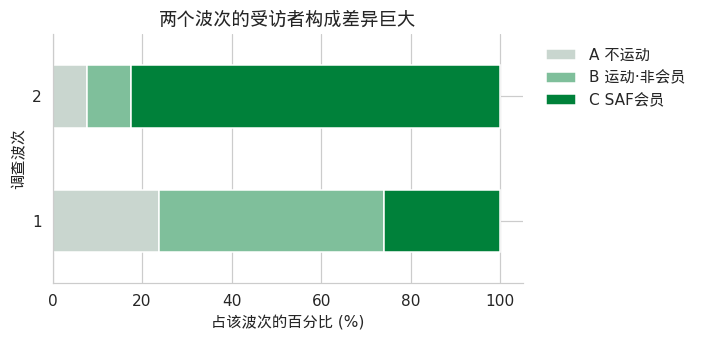

In [5]:
t = pd.crosstab(df["onada"], df["grup"])
t["合计"] = t.sum(axis=1)
display(t)
display((pd.crosstab(df["onada"], df["grup"], normalize="index") * 100).round(1).add_suffix(" (%)"))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
(pd.crosstab(df["onada"], df["grup"], normalize="index") * 100).plot.barh(stacked=True, ax=ax,
    color=["#c9d6cf", "#7fbf9b", "#00813a"])
ax.set_xlabel("占该波次的百分比 (%)"); ax.set_ylabel("调查波次")
ax.set_title("两个波次的受访者构成差异巨大")
ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

**这是本数据集最关键的"坑"：**

- 第 1 波（752 人）：约 24% 不运动、50% 非会员运动者、26% 会员，更接近"UAB 学生的一般情况"。
- 第 2 波（273 人）：**82% 是 SAF 会员**，不运动者只有 8%，而且**所有人都被问到了频率**。第 2 波显然是通过 SAF 自己的渠道（例如会员邮件）补发的。

**含义**
1. 总体样本里"会员/运动者"**被高估**，不能把 1,025 人的比例直接当作全校比例（比如不能说"全校 80% 的人运动"）。
2. 做"会员 vs 非会员"的比较时，两波的混合可能带来混杂 → 后面会做"只看第 1 波"和"回归里控制波次"的稳健性检查。

## 3. 样本画像

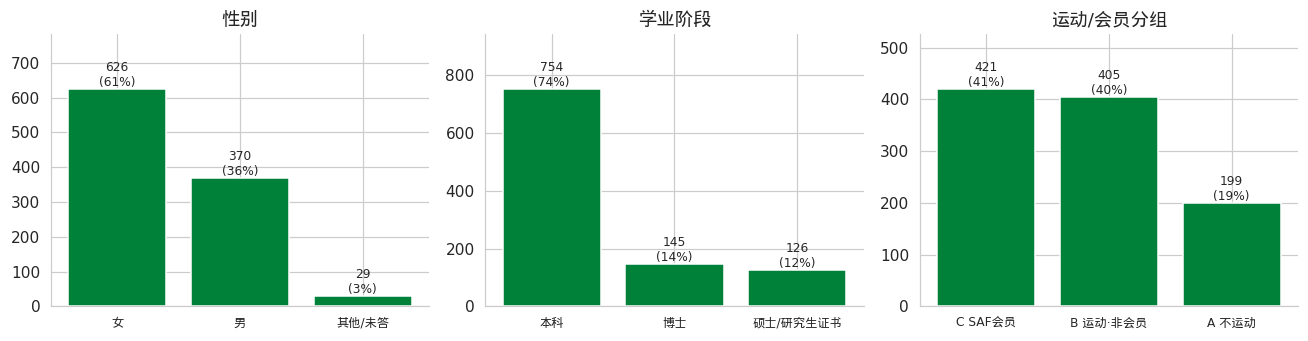

各组的性别 / 学业阶段构成 (%，按行)：


gen,其他/未答,女,男
grup,,,
A 不运动,4.0,66.3,29.6
B 运动·非会员,3.2,58.0,38.8
C SAF会员,1.9,61.5,36.6


est,博士,本科,硕士/研究生证书
grup,,,
A 不运动,10.6,75.4,14.1
B 运动·非会员,11.9,75.6,12.6
C SAF会员,18.1,70.8,11.2


In [6]:
G = {"Dona": "女", "Home": "男", "Altres o no contesta": "其他/未答"}
E = {"Grau": "本科", "Màster o postgrau": "硕士/研究生证书", "Doctorat": "博士"}
df["gen"] = df["genere"].map(G)
df["est"] = df["estudis"].map(E)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (col, title) in zip(axes, [("gen", "性别"), ("est", "学业阶段"), ("grup", "运动/会员分组")]):
    vc = df[col].value_counts()
    ax.bar(vc.index.astype(str), vc.values, color="#00813a")
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v}\n({v/len(df)*100:.0f}%)", ha="center", va="bottom", fontsize=8)
    ax.set_title(title); ax.set_ylim(0, vc.max() * 1.25); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

print("各组的性别 / 学业阶段构成 (%，按行)：")
display((pd.crosstab(df["grup"], df["gen"], normalize="index") * 100).round(1))
display((pd.crosstab(df["grup"], df["est"], normalize="index") * 100).round(1))

- 女性占 61%，本科生占 74%。会员组里**博士生比例更高**（约 18%，不运动组和非会员运动组约 11–12%）——后面回归会控制学业阶段。
- 注意：问卷没有 UAB 全校的性别/学业阶段分布可对照，所以**无法判断样本对全校的代表性**。

## 4. 结果变量的构造

问卷里的"结果"主要有四类，这里把它们变成可以比较的数值：

| 结果 | 构造方式 |
|---|---|
| **身体健康良好** | 自评"好"或"很好" → 1 |
| **情绪良好** | 自评"好"或"很好" → 1 |
| **压力分（PSS-4）** | 4 道题 *Mai=0 … Molt sovint=4*，第 3 题（"有信心掌控责任"）是**正向表述，需反向计分**；总分 0–16，**越高压力越大** |
| **睡眠** | 睡眠 ≥7 小时 / 睡眠质量自评"好或很好" |
| **归属感** | 4 道五点 Likert（1=完全不同意 … 5=完全同意） |

In [7]:
SALUT = ["Molt dolenta", "Dolenta", "Ni bona ni dolenta", "Bona", "Molt bona"]
EMO = ["Molt dolent", "Dolent", "Ni bo ni dolent", "Bo", "Molt bo"]
df["ph"] = df["salut_fisica"].isin(["Bona", "Molt bona"]).astype(int)       # 身体健康好
df["em"] = df["estat_emocional"].isin(["Bo", "Molt bo"]).astype(int)        # 情绪好

FREQ = {"1 vegada a la setmana": "每周1次", "2-3 vegades a la setmana": "每周2-3次",
        "4-5 vegades a la setmana": "每周4-5次", "Més de 5 vegades a la setmana": "每周>5次"}
FREQ_ORD = list(FREQ.values())
df["freq_zh"] = pd.Categorical(df["freq"].map(FREQ), FREQ_ORD, ordered=True)
df["freq_n"] = df["freq_zh"].cat.codes.where(df["freq_zh"].notna()) + 1   # 1..4

# PSS-4
PSSMAP = {"Mai": 0, "Gairebé mai": 1, "De vegades": 2, "Sovint": 3, "Molt sovint": 4}
P = df[["pss1", "pss2", "pss3", "pss4"]].apply(lambda s: s.map(PSSMAP))
P["pss3"] = 4 - P["pss3"]                       # 反向计分
df["pss"] = P.sum(axis=1)

# 内部一致性（Cronbach α）：看这 4 题合成一个分数合不合理
k = P.shape[1]
alpha = k / (k - 1) * (1 - P.var().sum() / P.sum(axis=1).var())
print(f"PSS-4 Cronbach α = {alpha:.2f}   (>0.7 视为可接受，反向计分后一致性良好)")
print(df["pss"].describe().round(2).to_string())

# 睡眠
df["son7"] = df["hores_son"].isin(["7-8 hores", "Més de 8 hores"]).astype(int)
df["son_q"] = df["qualitat_son"].isin(["Bona", "Molt bona"]).astype(int)
df["descansat"] = df["descans"].isin(["D’acord", "Totalment d’acord"]).astype(int)

# 归属感 Likert
LIK = {"Totalment en desacord": 1, "En desacord": 2, "Ni d’acord ni desacord": 3, "D’acord": 4, "Totalment d’acord": 5}
PERT = ["pertinenca", "opinio", "creixement", "records"]
for c in PERT:
    df[c + "_n"] = df[c].map(LIK)
df["pert_idx"] = df[[c + "_n" for c in PERT]].mean(axis=1)   # 4 题均值

# 二分类比例的 Wilson 95% 置信区间
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def prop_table(data, by, cols):
    # 返回每个分组下各二分类变量的比例及 n
    out = []
    for g, sub in data.groupby(by, observed=True):
        row = {"分组": g, "n": len(sub)}
        for c in cols: row[c] = sub[c].mean() * 100
        out.append(row)
    return pd.DataFrame(out).set_index("分组")

PSS-4 Cronbach α = 0.80   (>0.7 视为可接受，反向计分后一致性良好)
count    1025.0
mean        7.4
std         3.2
min         0.0
25%         5.0
50%         7.0
75%        10.0
max        16.0


## 5. 问题一：运动本身带来什么？（A 不运动 vs 运动者）

,n,身体健康好(%),情绪好(%),睡≥7h(%),睡眠质量好(%),PSS压力均分(0-16)
分组,,,,,,
A 不运动,199,30.7,35.2,67.3,37.2,8.7
B 运动·非会员,405,79.8,63.5,82.7,53.3,7.1
C SAF会员,421,77.4,63.2,82.7,51.5,7.1


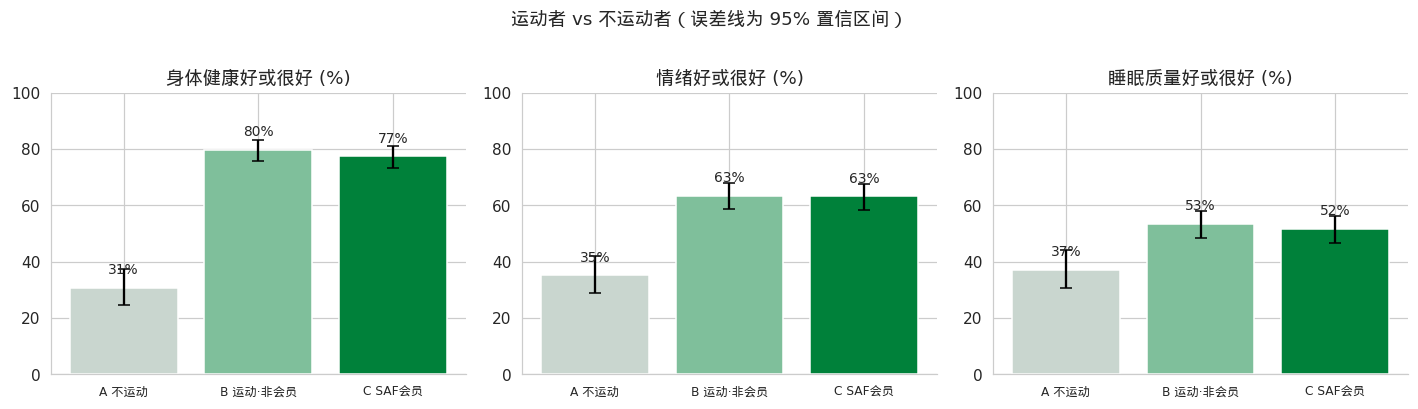

身体健康好    运动者  78.6%  vs 不运动者  30.7%   卡方检验 p = 5.12e-39
情绪好      运动者  63.3%  vs 不运动者  35.2%   卡方检验 p = 9.54e-13
睡眠质量好    运动者  52.4%  vs 不运动者  37.2%   卡方检验 p = 1.57e-04
睡≥7h     运动者  82.7%  vs 不运动者  67.3%   卡方检验 p = 2.19e-06
PSS 压力分  运动者 7.10 vs 不运动者 8.66   Mann-Whitney p = 5.88e-10

每晚睡眠时长分布 (% 按组)：


hores_son,1-3 hores,4-6 hores,7-8 hores,Més de 8 hores
grup,,,,
A 不运动,0.5,32.2,58.3,9.0
B 运动·非会员,0.5,16.8,70.4,12.3
C SAF会员,0.2,17.1,69.4,13.3


In [8]:
res = prop_table(df, "grup", ["ph", "em", "son7", "son_q"]).rename(columns={
    "ph": "身体健康好(%)", "em": "情绪好(%)", "son7": "睡≥7h(%)", "son_q": "睡眠质量好(%)"})
res["PSS压力均分(0-16)"] = df.groupby("grup", observed=True)["pss"].mean()
display(res.round(1))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
colors = ["#c9d6cf", "#7fbf9b", "#00813a"]
for ax, (c, t) in zip(axes, [("ph", "身体健康好或很好 (%)"), ("em", "情绪好或很好 (%)"), ("son_q", "睡眠质量好或很好 (%)")]):
    vals, los, his = [], [], []
    for g in GRUPS:
        s = df.loc[df["grup"] == g, c]; lo, hi = wilson(s.sum(), len(s))
        vals.append(s.mean() * 100); los.append(lo * 100); his.append(hi * 100)
    vals, los, his = map(np.array, (vals, los, his))
    ax.bar(GRUPS, vals, color=colors, yerr=[vals - los, his - vals], capsize=4)
    for i, v in enumerate(vals): ax.text(i, v + 5, f"{v:.0f}%", ha="center", fontsize=9)
    ax.set_title(t); ax.set_ylim(0, 100); ax.tick_params(axis="x", labelsize=8)
fig.suptitle("运动者 vs 不运动者（误差线为 95% 置信区间）", y=1.02)
plt.tight_layout(); plt.show()

# 显著性检验：A vs (B+C)
mov = df["grup"].ne("A 不运动")
for c, name in [("ph", "身体健康好"), ("em", "情绪好"), ("son_q", "睡眠质量好"), ("son7", "睡≥7h")]:
    p = stats.chi2_contingency(pd.crosstab(mov, df[c]))[1]
    print(f"{name:8s} 运动者 {df.loc[mov, c].mean()*100:5.1f}%  vs 不运动者 {df.loc[~mov, c].mean()*100:5.1f}%   卡方检验 p = {p:.2e}")
u = stats.mannwhitneyu(df.loc[mov, "pss"], df.loc[~mov, "pss"])
print(f"PSS 压力分  运动者 {df.loc[mov,'pss'].mean():.2f} vs 不运动者 {df.loc[~mov,'pss'].mean():.2f}   Mann-Whitney p = {u.pvalue:.2e}")

print("\n每晚睡眠时长分布 (% 按组)：")
display((pd.crosstab(df["grup"], df["hores_son"], normalize="index")[["1-3 hores", "4-6 hores", "7-8 hores", "Més de 8 hores"]] * 100).round(1))

**解读**

- **身体健康**：不运动者仅 **31%** 自评良好，运动者约 **79%**——差距接近 **48 个百分点**，是全问卷里最大、最稳的关联。
- **情绪**：不运动者 35% 情绪良好，运动者约 63%。
- **压力（PSS-4）**：不运动者均分 8.7，运动者约 7.1，低约 1.5 分（0–16 量表上约相当于 0.5 个标准差）。
- **睡眠**：不运动者里 32% 每晚只睡 4–6 小时（运动者约 17%）。

四项全部显著，方向一致：**运动者的健康、情绪、压力、睡眠都更好**。
但记住：不运动的人里，可能本身就有人是因为身体不好或压力大才没法运动（反向因果）。

## 6. 问题二：运动频率的"剂量-反应"关系

赛题幻灯片已经给出了一张"身体健康 vs 每周运动天数"的图。这里**复现并扩展**它，并回答"从 1–3 次到 4 次以上有多大差别"。

> 注意：**频率题只有 826 名运动者里的 720 人回答**（见 2.1），"不运动"视为 0 次。

,n,身体健康好,情绪好,睡眠质量好,PSS均分
freq_full,,,,,
不运动,199,30.7,35.2,37.2,8.66
每周1次,84,51.2,52.4,45.2,7.58
每周2-3次,349,73.9,57.6,47.9,7.55
每周4-5次,213,88.7,74.6,60.6,6.65
每周>5次,74,98.6,78.4,62.2,5.53


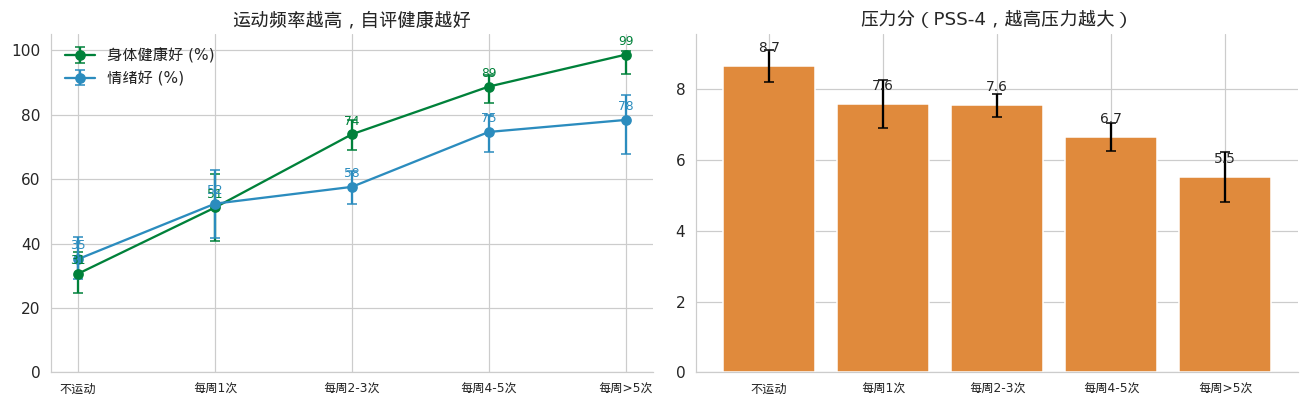

In [9]:
lv = ["不运动"] + FREQ_ORD
df["freq_full"] = pd.Categorical(
    np.where(df["grup"].eq("A 不运动"), "不运动", df["freq_zh"].astype(object)), lv, ordered=True)
sub = df[df["freq_full"].notna() & (df["freq_full"].astype(str) != "nan")]

tab = sub.groupby("freq_full", observed=True).agg(n=("id", "size"), 身体健康好=("ph", "mean"),
        情绪好=("em", "mean"), 睡眠质量好=("son_q", "mean"), PSS均分=("pss", "mean"))
for c in ["身体健康好", "情绪好", "睡眠质量好"]: tab[c] = (tab[c] * 100).round(1)
tab["PSS均分"] = tab["PSS均分"].round(2)
display(tab)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(lv))
for c, lab, col in [("ph", "身体健康好 (%)", "#00813a"), ("em", "情绪好 (%)", "#2b8cbe")]:
    g = sub.groupby("freq_full", observed=True)[c]
    m = g.mean() * 100
    ci = np.array([wilson(g.get_group(l).sum(), len(g.get_group(l))) for l in lv]) * 100
    ax[0].errorbar(x, m, yerr=[m - ci[:, 0], ci[:, 1] - m], marker="o", capsize=3, label=lab, color=col)
    for xi, v in zip(x, m): ax[0].text(xi, v + 3, f"{v:.0f}", ha="center", fontsize=8, color=col)
ax[0].set_xticks(x); ax[0].set_xticklabels(lv, fontsize=8); ax[0].set_ylim(0, 105)
ax[0].set_title("运动频率越高，自评健康越好"); ax[0].legend(frameon=False)
g = sub.groupby("freq_full", observed=True)["pss"]
ax[1].bar(lv, g.mean(), color="#e08a3c", yerr=1.96 * g.std() / np.sqrt(g.size()), capsize=3)
for i, v in enumerate(g.mean()): ax[1].text(i, v + 0.4, f"{v:.1f}", ha="center", fontsize=9)
ax[1].set_title("压力分（PSS-4，越高压力越大）"); ax[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

In [10]:
# 针对赛题提示 "从 1-3 天到 4 天以上"：把频率合并为 低(1-3次) / 高(≥4次) 并检验
sub2 = df[df["freq_zh"].notna()].copy()
sub2["高频"] = np.where(sub2["freq_n"] >= 3, "每周≥4次", "每周1-3次")
t2 = sub2.groupby("高频").agg(n=("id", "size"), 身体健康好=("ph", "mean"), 情绪好=("em", "mean"), PSS均分=("pss", "mean"))
t2[["身体健康好", "情绪好"]] = (t2[["身体健康好", "情绪好"]] * 100).round(1); t2["PSS均分"] = t2["PSS均分"].round(2)
display(t2)
for c in ["ph", "em"]:
    print(c, "卡方 p =", f"{stats.chi2_contingency(pd.crosstab(sub2['高频'], sub2[c]))[1]:.2e}")
print("PSS Mann-Whitney p =", f"{stats.mannwhitneyu(sub2.loc[sub2['高频']=='每周≥4次','pss'], sub2.loc[sub2['高频']=='每周1-3次','pss']).pvalue:.2e}")

,n,身体健康好,情绪好,PSS均分
高频,,,,
每周1-3次,433,69.5,56.6,7.56
每周≥4次,287,91.3,75.6,6.36


ph 卡方 p = 8.17e-12
em 卡方 p = 2.84e-07
PSS Mann-Whitney p = 1.46e-06


**解读**

- 身体健康好的比例随频率**单调上升**：不运动 31% → 每周 1 次 51% → 2–3 次 74% → 4–5 次 89% → >5 次 99%（与赛题幻灯片完全一致，可作为"每个数字都能溯源"的校验）。
- 情绪好的比例同样上升（52% → 58% → 75% → 78%）。
- **压力分有明显的"拐点"**：每周 1 次和 2–3 次的压力分几乎一样（约 7.6），**到 4 次以上才明显下降**（4–5 次 6.7，>5 次 5.5）。也就是说：对**心理压力**而言，"从 1–3 次到 4 次以上"才是有效门槛；对**身体健康自评**则是每增加一档都有提升。
- 这正好呼应赛题线 2 的提示："一个干预，让人从每周 1–3 天变成 4 天以上"，数据上最值得瞄准的是**每周 2–3 次这一大群人**（349 人，是最大的一档）。

## 7. 问题三：SAF 会员在"运动"之外，还额外带来什么？（B vs C）

这是赛题要求的"**把运动和成为会员分开**"：既然 B、C 都在运动，二者的差别才是"SAF 的边际贡献"的大致估计。

In [11]:
bc = df[df["grup"] != "A 不运动"].copy()
rows = []
def add_bin(c, name):
    a, b = bc.loc[bc.grup == "B 运动·非会员", c], bc.loc[bc.grup == "C SAF会员", c]
    p = stats.chi2_contingency(pd.crosstab(bc["grup"], bc[c]))[1]
    rows.append([name, a.mean() * 100, b.mean() * 100, (b.mean() - a.mean()) * 100, p])
def add_num(c, name, scale=1):
    a, b = bc.loc[bc.grup == "B 运动·非会员", c].dropna(), bc.loc[bc.grup == "C SAF会员", c].dropna()
    p = stats.mannwhitneyu(a, b).pvalue
    rows.append([name, a.mean(), b.mean(), b.mean() - a.mean(), p])

print("—— 百分比类指标（单位：%） ——")
for c, n in [("ph", "身体健康好"), ("em", "情绪好"), ("son7", "睡≥7h"), ("son_q", "睡眠质量好"), ("descansat", "醒来有休息感")]:
    add_bin(c, n)
for c, n in [("amistats", "因运动结交朋友"), ("voluntariat", "参加过体育志愿/赛事"), ("organs", "参与学生组织/管理机构")]:
    bc[c + "_b"] = bc[c].eq("Sí.").astype(int); add_bin(c + "_b", n)
t = pd.DataFrame(rows, columns=["指标", "非会员运动者", "SAF会员", "差值(C-B)", "p值"]).set_index("指标")
display(t.round(3))

rows = []
print("—— 均值类指标 ——")
add_num("pss", "PSS压力分(0-16，越低越好)")
for c, z in [("pertinenca", "课堂之外有归属感"), ("opinio", "意见被大学重视"), ("creixement", "大学帮我个人成长"), ("records", "与大学里的人有积极回忆")]:
    add_num(c + "_n", z + "(1-5)")
t2 = pd.DataFrame(rows, columns=["指标", "非会员运动者", "SAF会员", "差值(C-B)", "p值"]).set_index("指标")
display(t2.round(3))

—— 百分比类指标（单位：%） ——


,非会员运动者,SAF会员,差值(C-B),p值
指标,,,,
身体健康好,79.753,77.435,-2.318,0.467
情绪好,63.457,63.183,-0.274,0.992
睡≥7h,82.716,82.660,-0.056,1.000
睡眠质量好,53.333,51.544,-1.789,0.656
醒来有休息感,51.605,46.793,-4.812,0.189
因运动结交朋友,70.864,62.233,-8.631,0.011
参加过体育志愿/赛事,14.815,19.240,4.425,0.110
参与学生组织/管理机构,9.383,13.302,3.919,0.096


—— 均值类指标 ——


,非会员运动者,SAF会员,差值(C-B),p值
指标,,,,
PSS压力分(0-16，越低越好),7.054,7.150,0.095,0.618
课堂之外有归属感(1-5),2.563,3.359,0.796,0.000
意见被大学重视(1-5),2.975,3.057,0.082,0.266
大学帮我个人成长(1-5),2.867,3.387,0.521,0.000
与大学里的人有积极回忆(1-5),3.933,4.226,0.292,0.000


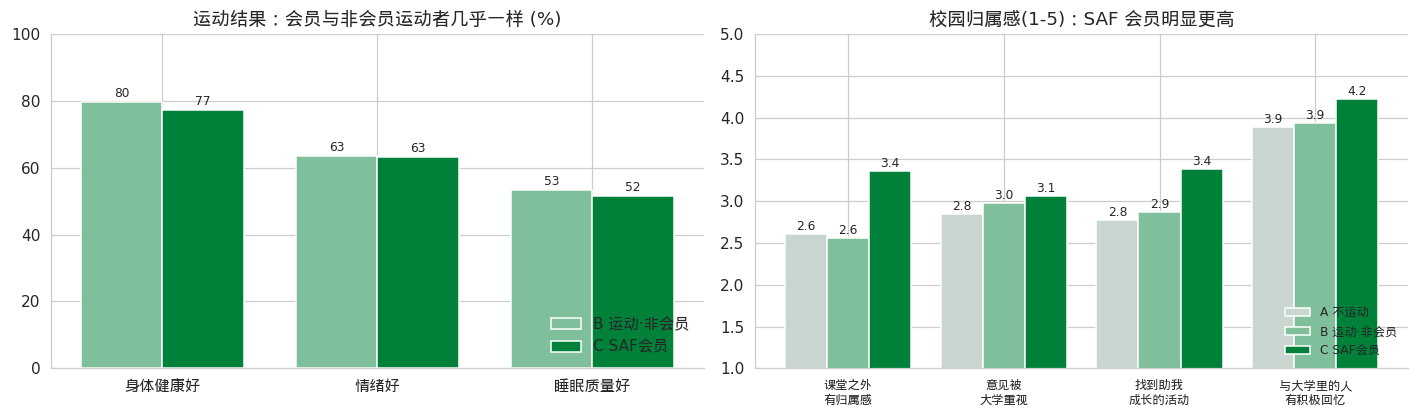

In [12]:
# 可视化：会员 vs 非会员 —— 左：运动结果（几乎无差别）；右：校园归属感（差别很大）
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
items = [("ph", "身体健康好"), ("em", "情绪好"), ("son_q", "睡眠质量好")]
x = np.arange(len(items)); w = 0.38
for j, (g, col) in enumerate([("B 运动·非会员", "#7fbf9b"), ("C SAF会员", "#00813a")]):
    vals = [bc.loc[bc.grup == g, c].mean() * 100 for c, _ in items]
    ax[0].bar(x + (j - .5) * w, vals, w, label=g, color=col)
    for xi, v in zip(x + (j - .5) * w, vals): ax[0].text(xi, v + 1.5, f"{v:.0f}", ha="center", fontsize=8)
ax[0].set_xticks(x); ax[0].set_xticklabels([n for _, n in items]); ax[0].set_ylim(0, 100)
ax[0].set_title("运动结果：会员与非会员运动者几乎一样 (%)"); ax[0].legend(frameon=False, loc="lower right")

items2 = [("pertinenca_n", "课堂之外\n有归属感"), ("opinio_n", "意见被\n大学重视"), ("creixement_n", "找到助我\n成长的活动"), ("records_n", "与大学里的人\n有积极回忆")]
x = np.arange(len(items2))
for j, (g, col) in enumerate([("A 不运动", "#c9d6cf"), ("B 运动·非会员", "#7fbf9b"), ("C SAF会员", "#00813a")]):
    vals = [df.loc[df.grup == g, c].mean() for c, _ in items2]
    ax[1].bar(x + (j - 1) * 0.27, vals, 0.27, label=g, color=col)
    for xi, v in zip(x + (j - 1) * 0.27, vals): ax[1].text(xi, v + .05, f"{v:.1f}", ha="center", fontsize=8)
ax[1].set_xticks(x); ax[1].set_xticklabels([n for _, n in items2], fontsize=8); ax[1].set_ylim(1, 5)
ax[1].set_title("校园归属感(1-5)：SAF 会员明显更高"); ax[1].legend(frameon=False, loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**解读：这是全数据集最有价值的发现 —— "SAF 的价值不在身体，而在归属"**

1. **身体/情绪/压力/睡眠**：会员与"同样在运动的非会员"几乎没有差别（身体健康好 77% vs 80%，情绪好 63% vs 64%，压力分 7.15 vs 7.05，*p* 均远大于 0.05）。
   → **不能**对外宣称"加入 SAF 会让你更健康"；数据支持的说法是"**运动**让你更健康，SAF 是一个运动的场所"。
2. **校园归属感**：会员显著高于两个对照组（同样运动的非会员、不运动者）：
   - "课堂之外有归属感"：会员 **3.36** vs 非会员运动者 **2.56**（*p* ≈ 1e-20）；
   - "通过大学找到助我成长的活动"：**3.39** vs **2.87**；
   - "与大学里的人有积极回忆"：4.23 vs 3.93。
   - **非会员运动者的归属感和不运动者几乎一样**（2.56 vs 2.61）——也就是说，**只有通过 SAF 运动才与归属感挂钩，自己在校外运动则没有**。这是"SAF 特有的价值"最清晰的证据。
3. **没有差别的校园指标**："意见被大学重视"两组相当（2.98 vs 3.06，*p*=0.27）；体育志愿/赛事参与（19% vs 15%，*p*=0.11）和学生组织参与（13% vs 9%，*p*=0.10）会员略高，但**差异不显著**，不能当结论。
4. **一个反直觉的点**：*"因运动结交朋友"* 会员反而更低（62% vs 71%，*p*=0.011，显著）。可能的解释：会员更多是"自己去健身房"，而非会员更多是通过球队/朋友圈运动——值得在第二份问卷中追问**"与谁运动"**。（这只是猜测，数据本身不能验证。）

> 同样要提防**选择偏差**：可能是"本来就更融入学校的人"才会加入 SAF，而不是 SAF 让人更有归属感。

## 8. 控制混杂因素后，结论还稳吗？（回归）

前面的比较都是"粗"的：A/B/C 三组在性别、学业阶段、调查波次上构成不同。这里用回归同时控制它们。

- 身体健康好、情绪好 → **逻辑回归**，报告**优势比 OR**（OR>1 表示该因素下"好"的几率更高）；
- 压力分 → **线性回归**，报告系数 *b*（负数表示压力更低）。

In [13]:
d = df.copy()
d["grp"] = d["grup"].astype(str).str[0]          # A / B / C
d["wave"] = d["onada"].astype(str)

def pretty(idx):
    idx = re.sub(r'C\((\w+), Treatment\("?(.+?)"?\)\)\[T\.(.+?)\]', r'\1: \3 (对照: \2)', idx)
    return idx.replace('Intercept', '截距')

def or_table(res):
    ci = res.conf_int()
    t = pd.DataFrame({"OR": np.exp(res.params), "95%下限": np.exp(ci[0]), "95%上限": np.exp(ci[1]), "p值": res.pvalues})
    t.index = [pretty(i) for i in t.index]; return t.round(3)

RHS = 'C(grp, Treatment("A")) + C(gen, Treatment("男")) + C(est, Treatment("本科")) + C(wave, Treatment("1"))'
print("== 身体健康好（逻辑回归，OR）==")
m_ph = smf.logit("ph ~ " + RHS, d).fit(disp=0); display(or_table(m_ph))
print("== 情绪好（逻辑回归，OR）==")
m_em = smf.logit("em ~ " + RHS, d).fit(disp=0); display(or_table(m_em))
print("== PSS 压力分（线性回归，b）==")
m_pss = smf.ols("pss ~ " + RHS, d).fit()
t = pd.DataFrame({"b": m_pss.params, "95%下限": m_pss.conf_int()[0], "95%上限": m_pss.conf_int()[1], "p值": m_pss.pvalues})
t.index = [pretty(i) for i in t.index]; display(t.round(3))

== 身体健康好（逻辑回归，OR）==


,OR,95%下限,95%上限,p值
截距,0.550,0.376,0.805,0.002
grp: B (对照: A),8.867,6.004,13.095,0.000
grp: C (对照: A),8.915,5.831,13.628,0.000
gen: 其他/未答 (对照: 男),0.388,0.167,0.904,0.028
gen: 女 (对照: 男),0.769,0.562,1.053,0.102
est: 博士 (对照: 本科),0.766,0.507,1.157,0.206
est: 硕士/研究生证书 (对照: 本科),1.310,0.819,2.096,0.259
wave: 2 (对照: 1),0.765,0.521,1.124,0.173


== 情绪好（逻辑回归，OR）==


,OR,95%下限,95%上限,p值
截距,0.717,0.503,1.023,0.066
grp: B (对照: A),3.160,2.209,4.520,0.000
grp: C (对照: A),3.088,2.104,4.532,0.000
gen: 其他/未答 (对照: 男),0.226,0.096,0.533,0.001
gen: 女 (对照: 男),0.726,0.553,0.954,0.021
est: 博士 (对照: 本科),0.773,0.534,1.119,0.172
est: 硕士/研究生证书 (对照: 本科),1.008,0.677,1.500,0.969
wave: 2 (对照: 1),1.039,0.742,1.455,0.824


== PSS 压力分（线性回归，b）==


,b,95%下限,95%上限,p值
截距,7.846,7.321,8.370,0.000
grp: B (对照: A),-1.483,-2.010,-0.957,0.000
grp: C (对照: A),-1.395,-1.960,-0.830,0.000
gen: 其他/未答 (对照: 男),2.192,1.020,3.364,0.000
gen: 女 (对照: 男),1.157,0.758,1.556,0.000
est: 博士 (对照: 本科),-0.413,-0.965,0.139,0.143
est: 硕士/研究生证书 (对照: 本科),-0.029,-0.613,0.555,0.923
wave: 2 (对照: 1),0.043,-0.454,0.541,0.864


**解读（控制性别、学业阶段、波次后）**

- **运动 ≫ 会员身份**：与不运动者相比，非会员运动者"身体健康好"的几率约是 **8.9 倍**，会员也约 **8.9 倍**——两者没有差别。情绪好的几率约 3.1–3.2 倍，压力分低约 1.4–1.5 分，同样两组一致。
- **性别差异独立存在**：女性情绪好的几率更低（OR≈0.73），压力分高约 **1.2 分**；"其他/未答"组压力分高约 2.2 分、情绪好几率仅 0.23 倍、身体健康好几率 0.39 倍——这一群体心理负担明显更重，值得单独关注（但**仅 29 人**，区间很宽，需谨慎）。
- 学业阶段在控制其他因素后影响不显著。
- **波次系数在三个模型里都不显著**（*p* = 0.17 / 0.82 / 0.86），说明"两波人群不同"没有扭曲上面的结论；下一节再用"只看第 1 波"做对照。

In [14]:
# 频率的连续效应：在运动者中，每升高一档频率（1→2→3→4）身体健康好的几率变化
pr = d[d["freq_n"].notna()].copy()
m_f = smf.logit('ph ~ freq_n + C(grp, Treatment("B")) + C(gen, Treatment("男")) + C(est, Treatment("本科"))', pr).fit(disp=0)
display(or_table(m_f))

,OR,95%下限,95%上限,p值
截距,0.385,0.180,0.823,0.014
grp: C (对照: B),0.981,0.667,1.443,0.924
gen: 其他/未答 (对照: 男),0.328,0.113,0.958,0.041
gen: 女 (对照: 男),0.924,0.612,1.397,0.709
est: 博士 (对照: 本科),0.723,0.443,1.179,0.194
est: 硕士/研究生证书 (对照: 本科),1.377,0.743,2.551,0.309
freq_n,2.912,2.201,3.853,0.000


- 在运动者中，**频率每升高一档，身体健康好的几率约变为 2.9 倍**（*p*<0.001），而**是否为会员**在控制频率后 OR≈0.98（无差别）。结论稳定。

## 9. 稳健性检查：只用第 1 波（更接近全校人群）重做 B vs C

第 2 波以会员为主，是否会"制造"出会员/非会员的差异？只保留第 1 波再看一次。

In [15]:
w1 = df[(df["onada"] == 1) & df["grup"].ne("A 不运动")]
rows = []
for c, n in [("ph", "身体健康好 (%)"), ("em", "情绪好 (%)"), ("son_q", "睡眠质量好 (%)")]:
    a, b = w1.loc[w1.grup == "B 运动·非会员", c], w1.loc[w1.grup == "C SAF会员", c]
    rows.append([n, a.mean() * 100, b.mean() * 100, stats.chi2_contingency(pd.crosstab(w1["grup"], w1[c]))[1]])
for c, n in [("pss", "PSS压力分"), ("pertinenca_n", "课堂之外有归属感(1-5)"), ("creixement_n", "找到助我成长的活动(1-5)")]:
    a, b = w1.loc[w1.grup == "B 运动·非会员", c].dropna(), w1.loc[w1.grup == "C SAF会员", c].dropna()
    rows.append([n, a.mean(), b.mean(), stats.mannwhitneyu(a, b).pvalue])
t = pd.DataFrame(rows, columns=["指标", "非会员运动者", "SAF会员", "p值"]).set_index("指标")
print(f"仅第1波：非会员运动者 n={(w1.grup=='B 运动·非会员').sum()}，会员 n={(w1.grup=='C SAF会员').sum()}")
display(t.round(3))

仅第1波：非会员运动者 n=378，会员 n=196


,非会员运动者,SAF会员,p值
指标,,,
身体健康好 (%),80.159,80.612,0.985
情绪好 (%),63.228,61.735,0.795
睡眠质量好 (%),53.704,47.959,0.223
PSS压力分,7.042,7.214,0.447
课堂之外有归属感(1-5),2.548,3.327,0.000
找到助我成长的活动(1-5),2.868,3.311,0.000


**结论不变**：只看第 1 波，会员与非会员运动者在身体/情绪/压力/睡眠上依然没有显著差别，而**归属感依然显著更高**。这说明"SAF 的价值在归属而非健康"的结论**不是两波混合造成的假象**。

## 10. 会员时长：越久越好吗？

会员加入多久与身体/情绪是否有关？（仅 421 位会员）

In [16]:
TEMPS = ["Menys de 6 mesos", "6-12 mesos", "1-2 anys", "3-4 anys", "Més de 5 anys"]
TZ = {"Menys de 6 mesos": "<6个月", "6-12 mesos": "6-12个月", "1-2 anys": "1-2年", "3-4 anys": "3-4年", "Més de 5 anys": ">5年"}
m = df[df["grup"] == "C SAF会员"].copy()
m["temps"] = pd.Categorical(m["temps_abonat"].map(TZ), list(TZ.values()), ordered=True)
tt = m.groupby("temps", observed=True).agg(n=("id", "size"), 身体健康好=("ph", "mean"), 情绪好=("em", "mean"),
        PSS均分=("pss", "mean"), 归属感均值=("pertinenca_n", "mean"))
tt[["身体健康好", "情绪好"]] = (tt[["身体健康好", "情绪好"]] * 100).round(1); tt[["PSS均分", "归属感均值"]] = tt[["PSS均分", "归属感均值"]].round(2)
display(tt)
rho, p = stats.spearmanr(m["temps"].cat.codes, m["pertinenca_n"]); print(f"会员时长 vs 归属感：Spearman ρ={rho:.2f}, p={p:.3f}")
rho, p = stats.spearmanr(m["temps"].cat.codes, m["pss"]); print(f"会员时长 vs 压力分：Spearman ρ={rho:.2f}, p={p:.3f}")

,n,身体健康好,情绪好,PSS均分,归属感均值
temps,,,,,
<6个月,147,77.6,62.6,7.51,3.32
6-12个月,59,78.0,55.9,7.08,3.53
1-2年,115,81.7,66.1,6.90,3.30
3-4年,67,70.1,67.2,7.33,3.33
>5年,33,75.8,60.6,6.18,3.52


会员时长 vs 归属感：Spearman ρ=0.02, p=0.663
会员时长 vs 压力分：Spearman ρ=-0.07, p=0.169


- 各档会员时长的身体/情绪/压力指标**没有清晰的上升趋势**（每档 33–147 人，波动较大）。
- 注意"<6 个月"的会员最多（147 人），而 ">5 年" 只有 33 人 → **会员群体以新会员为主**，也可能意味着"留存"是个问题（但仅凭一次横断面数据无法断言，需要第二份问卷做追踪）。

## 11. 为什么运动？SAF 会员与非会员的动机、方式、好处感知

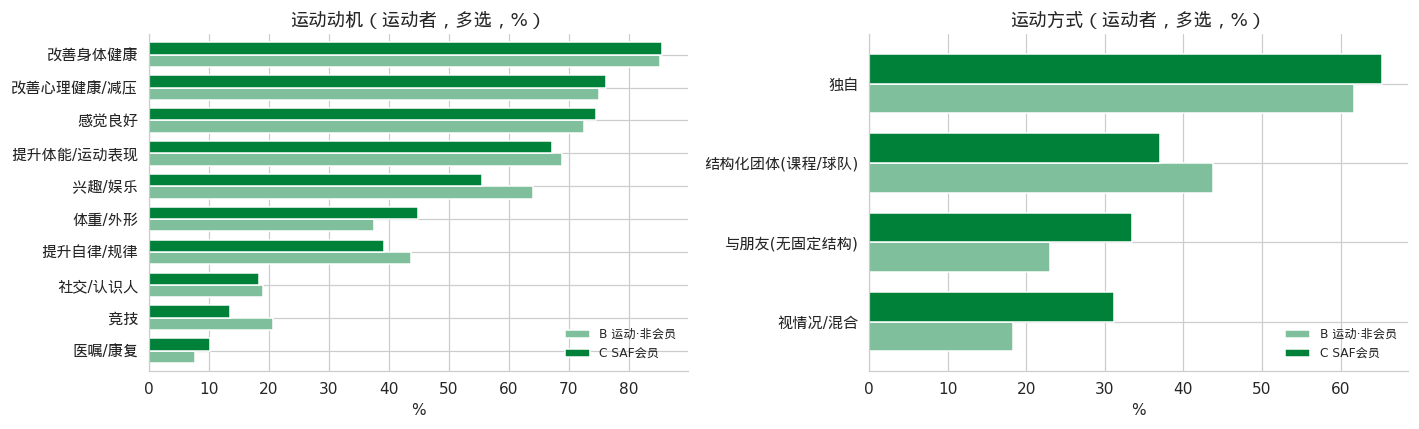

非会员运动者在哪里运动（多选，% 占 405 人）：


,%
on,
运动设施(健身房/球场/泳池),83.0
校外户外,34.8
在家,25.9
校内户外,2.2


In [17]:
MOT = {"Millorar la salut física.": "改善身体健康", "Millorar la salut mental o reduir l’estrès.": "改善心理健康/减压",
       "Sentir-te bé.": "感觉良好", "Millorar la condició física o el rendiment esportiu.": "提升体能/运动表现",
       "Per plaer o diversió.": "兴趣/娱乐", "Millorar l’organització personal, la rutina o la disciplina.": "提升自律/规律",
       "Per qüestions de pes o aspecte físic.": "体重/外形", "Socialitzar o conèixer gent.": "社交/认识人",
       "Competir.": "竞技", "Per recomanació mèdica o rehabilitació.": "医嘱/康复"}
COM = {"De manera individual.": "独自", "En grup estructurat (classes dirigides, equip, grup d’entrenament, etc.).": "结构化团体(课程/球队)",
       "Amb amics o companys però sense estructura formal.": "与朋友(无固定结构)", "Depèn del dia o amb una combinació de diverses opcions.": "视情况/混合"}
ON = {"A instal·lacions esportives (gimnàs, pistes, piscines, etc.).": "运动设施(健身房/球场/泳池)", "A espais a l’aire lliure fora del campus de la UAB.": "校外户外",
      "A casa.": "在家", "A espais a l’aire lliure dins del campus de la UAB.": "校内户外"}

def multi(col, mapping, mask):
    s = df.loc[mask, col].dropna().str.split(";").explode().str.strip()
    n = df.loc[mask, col].notna().sum()
    return (s.map(mapping).value_counts() / n * 100), n

pr_mask = df["grup"].ne("A 不运动")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, mp, title in [(axes[0], "motius", MOT, "运动动机（运动者，多选，%）"), (axes[1], "com", COM, "运动方式（运动者，多选，%）")]:
    res = {}
    for g, col_c in [("B 运动·非会员", "#7fbf9b"), ("C SAF会员", "#00813a")]:
        res[g], n = multi(col, mp, df["grup"].eq(g))
    t = pd.DataFrame(res).fillna(0).sort_values("C SAF会员")
    t.plot.barh(ax=ax, color=["#7fbf9b", "#00813a"], width=.75)
    ax.set_title(title); ax.set_xlabel("%"); ax.set_ylabel(""); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print("非会员运动者在哪里运动（多选，% 占 405 人）：")
t, n = multi("on", ON, df["grup"].eq("B 运动·非会员")); display(t.round(1).to_frame("%"))

组,B 运动·非会员,C SAF会员
好处,,
更想保持健康生活,90.9,92.6
更有精力,85.2,88.1
专注力提升,75.6,75.3
更有条理,63.5,63.2
因运动交到朋友(是),70.9,62.2
培养团队/领导力等技能,48.4,47.3


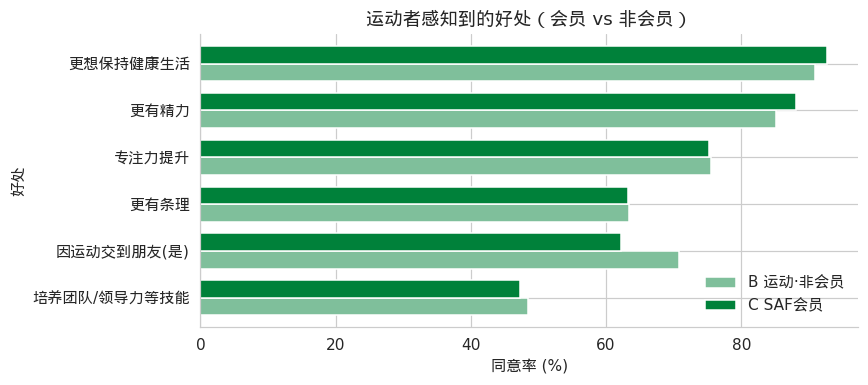

In [18]:
# 运动好处的"同意率"（同意+完全同意），运动者内部比较
AG = ["D’acord", "Totalment d’acord"]
ben = [("energia", "更有精力"), ("motivacio", "更想保持健康生活"), ("concentracio", "专注力提升"),
       ("organitzacio", "更有条理"), ("habilitats", "培养团队/领导力等技能")]
rows = []
for c, n in ben:
    for g in ["B 运动·非会员", "C SAF会员"]:
        s = df.loc[df.grup == g, c].dropna(); rows.append([n, g, s.isin(AG).mean() * 100])
rows.append(["因运动交到朋友(是)", "B 运动·非会员", df.loc[df.grup == "B 运动·非会员", "amistats"].eq("Sí.").mean() * 100])
rows.append(["因运动交到朋友(是)", "C SAF会员", df.loc[df.grup == "C SAF会员", "amistats"].eq("Sí.").mean() * 100])
t = pd.DataFrame(rows, columns=["好处", "组", "同意率(%)"]).pivot(index="好处", columns="组", values="同意率(%)")
display(t.sort_values("C SAF会员", ascending=False).round(1))

ax = t.sort_values("C SAF会员").plot.barh(figsize=(8, 3.6), color=["#7fbf9b", "#00813a"], width=.75)
ax.set_xlabel("同意率 (%)"); ax.set_title("运动者感知到的好处（会员 vs 非会员）"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**解读**

- **最主要的运动动机**：改善身体健康（705/826，约 85%）、改善心理健康/减压（约 76%）、感觉良好（约 74%）。**社交（19%）和竞技（17%）动机很少**——运动在这个群体里主要是"个人健康行为"，而不是社交行为。
- **运动方式**：以**独自运动**为主（525 人，约 64%），结构化团体仅 40%。→ 这与"社交归属"是 SAF 的差异化价值这一发现形成张力：**SAF 的会员多数仍是一个人运动**，如何把他们变成"社群"是潜在的运营方向。
- **会员 vs 非会员的运动方式有差别**：非会员运动者更多参加**结构化团体**（44% vs 会员 37%）和**竞技**（21% vs 14%），会员更多是"视情况/混合"和与朋友一起。这与第 7 节"因运动结交朋友"会员反而更低（62% vs 71%）是一致的——**球队/团体项目更容易交朋友**，而 SAF 会员的归属感来自别的东西（设施、课程、校园认同），而不是"运动社交"。（解释性推测，非因果证明。）
- **感知好处**：精力（>85%）、更想保持健康生活（>90%）最高；而"培养团队/领导力"（<50%）最低。**会员和非会员的感知几乎一致**，进一步印证了"好处来自运动本身"。
- 非会员运动者中，**83%（336/405）会去"运动设施（健身房/球场/泳池）"运动**，校内户外仅 2%。这个选项没有区分是不是 UAB 的设施，所以无法判断他们去的是校内还是校外健身房——这是第二份问卷必须补的一个问题。如果其中很多是校外健身房，那他们就是 SAF 最直接的潜在转化人群。

## 12. 情绪不佳时，原因是什么？

In [19]:
FAC = {"Pressió acadèmica": "学业压力", "Falta de temps o organització": "缺乏时间/组织", "Relacions socials o familiars": "社交/家庭关系",
       "Factors econòmics": "经济因素", "Salut física": "身体健康", "Factors polítics o socials": "政治/社会因素"}
n_ans = df["factors_malestar"].notna().sum()
ct = pd.crosstab(df["estat_emocional"], df["factors_malestar"].notna())
ct.columns = ["未回答", "已回答"]
print(f"回答了'情绪差的原因'的共 {n_ans} 人；他们的情绪自评分布：")
display(ct.reindex(EMO))

回答了'情绪差的原因'的共 294 人；他们的情绪自评分布：


,未回答,已回答
estat_emocional,,
Molt dolent,0,18
Dolent,3,164
Ni bo ni dolent,187,60
Bo,434,42
Molt bo,107,10


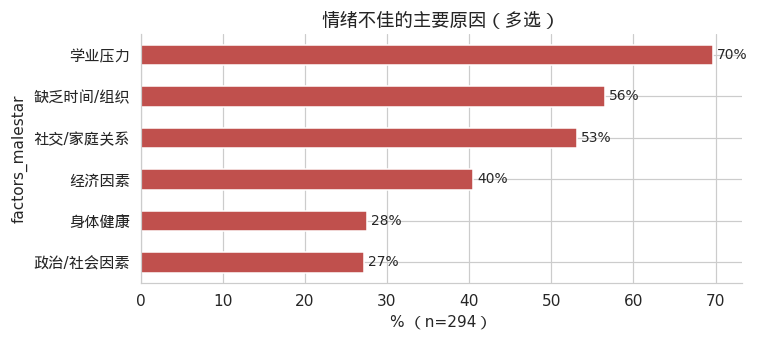

In [20]:
s = df["factors_malestar"].dropna().str.split(";").explode().str.strip().map(FAC)
t = (s.value_counts() / n_ans * 100).round(1)
ax = t.sort_values().plot.barh(figsize=(7, 3.2), color="#c0504d")
ax.set_xlabel(f"% （n={n_ans}）"); ax.set_title("情绪不佳的主要原因（多选）")
for i, v in enumerate(t.sort_values()): ax.text(v + .5, i, f"{v:.0f}%", va="center", fontsize=9)
plt.tight_layout(); plt.show()

- 学业压力（70%）和缺乏时间/组织（56%）是最主要的两个原因，其次是社交/家庭关系（53%）。这提示：**"时间/时段"是运动的真正障碍**——正好与线 1（SAF 空间在什么时段拥挤/空闲）接上：把"高峰时段"的需求分流到空闲时段，可能同时解决设施拥挤和学生的时间压力。
- ⚠️ **数据质量提示**：该题是给"情绪差/很差"的人设计的，但回答人数（约 294）**多于**自评差/很差的人数（185），说明跳题逻辑不严格，有一部分"情绪一般或好"的人也回答了。因此此处的百分比以"实际回答者"为分母，不是严格的"情绪差人群"。

## 13. 总结：给 SAF 的三条信息（每条带数字与上限）

> 要求："每个数字都能说明来源"。下面每条都标了来源（本 notebook 的哪一节）和**局限**。

**① 运动本身有很强的关联，4 次/周是压力的门槛。**
不运动者仅 31% 自评身体健康良好，运动者约 79%；每周运动 ≥4 次者压力分比 1–3 次者低约 1.2 分（7.56 → 6.36，*p*<0.001；身体健康好 91% vs 70%）。
*来源：第 5、6 节。上限：横断面，仅关联，可能存在反向因果；"每周 2–3 次"人群最多（349 人），是最值得推动加频的目标。*

**② 在"运动"之外，SAF 的独特价值是校园归属感，而不是更好的健康指标。**
会员"课堂之外有归属感"3.36 vs 非会员运动者 2.56（5 分制）；而身体/情绪/压力/睡眠两组几乎无差别（健康好 77% vs 80%）。非会员运动者的归属感与不运动者相同（2.56 vs 2.61）。
*来源：第 7、9 节（只用第 1 波结论不变）。上限：可能是"更融入学校的人才加入 SAF"（选择偏差）；不能写成"SAF 提升归属感"。*

**③ 样本偏向会员，且问卷有设计缺陷，下一轮要修。**
第 2 波 82% 是会员，因此总体比例不可外推；106 名非会员没有被问运动频率。
*来源：第 2 节。*

### 对第二份问卷（"明年我们测什么"）的建议
1. **所有运动者都回答"频率"和"运动场所"**，并加上"每周运动**分钟数**"或使用 IPAQ，而不是只用次数档位。
2. **用同样的随机抽样渠道**投放，不要在第 2 波只面向会员；记录**加入渠道**，才能去除选择偏差。
3. **追踪同一批人**（匿名但可配对的 ID）：测"新会员加入前后"的归属感、压力、睡眠变化，这是把关联推向因果的最低成本方法。
4. 增加"**与谁一起运动**"、"**为什么没有加入 SAF**"（价格/时间/不知道/设施）、"**最常去的时段**"，与线 1 的预订数据对接。
5. 增加"**使用 SAF 的频率**"（而不是仅"是不是会员"）——会员里也有人几乎不去。

### 本分析的局限
- 横断面 + 自评指标，**不能证明因果**；
- 样本是自愿填写，**自选择偏差**（第 2 波尤其严重）；
- 多重比较：本文做了很多检验，边缘显著的结果（如个别 *p*≈0.03）应谨慎；
- "其他/未答"性别组仅 29 人，结论波动大；
- PSS-4 为简版压力量表，仅用于组间比较，不能用于个体诊断。